# Experiment 8 — Classification Models (Iris Dataset)

**Covers:** Logistic Regression, KNN, Gaussian Naïve Bayes, accuracy, precision, recall, F1, AUC, odds ratios, confusion matrices, classification reports, ROC curves, KNN hyperparameter analysis and CSV results.

**Dataset:** **Iris** – `Iris.csv` from Kaggle ([uciml/iris](https://www.kaggle.com/datasets/uciml/iris)), 150 flowers, columns `Id, SepalLengthCm, SepalWidthCm, PetalLengthCm, PetalWidthCm, Species`.

**Data file:** keep `Iris.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\Iris.csv")`).

**Remember:** Split → Three models → fit/predict/probability → Metrics → ROC → Odds → K values → Compare.

**Why Versicolor vs Virginica?** The lab manual asks for binary classification. Setosa is perfectly separable from the other two species, so every model would score 100%; the two overlapping species give a meaningful comparison.

## Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("Iris.csv")

## 1. Prepare data

In [2]:
# Binary classification: Versicolor (0) vs Virginica (1)
cols = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
data = df[df["Species"] != "Iris-setosa"]

X = data[cols]
y = (data["Species"] == "Iris-virginica").astype(int)

print("Class mapping: 0 = Versicolor, 1 = Virginica")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Versicolor, 1 = Virginica
Species
0    50
1    50
Name: count, dtype: int64
Train: 80 Test: 20


## 2. Models (same loop for all three)


 Logistic
              precision    recall  f1-score   support

           0       0.90      0.90      0.90        10
           1       0.90      0.90      0.90        10

    accuracy                           0.90        20
   macro avg       0.90      0.90      0.90        20
weighted avg       0.90      0.90      0.90        20



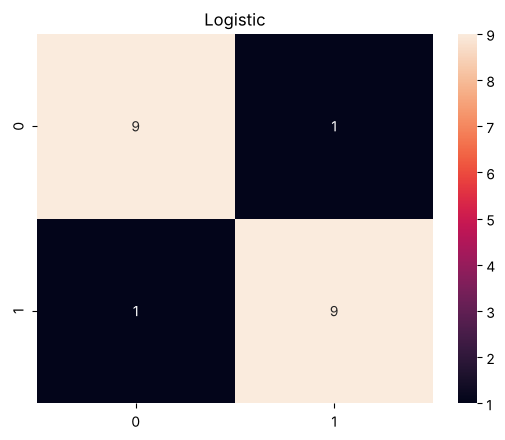


 KNN
              precision    recall  f1-score   support

           0       0.82      0.90      0.86        10
           1       0.89      0.80      0.84        10

    accuracy                           0.85        20
   macro avg       0.85      0.85      0.85        20
weighted avg       0.85      0.85      0.85        20



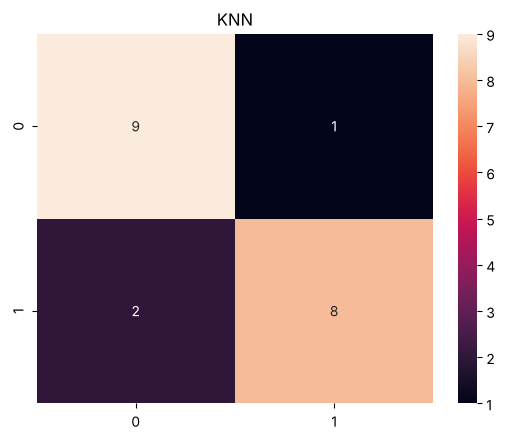


 Naive Bayes
              precision    recall  f1-score   support

           0       0.75      0.90      0.82        10
           1       0.88      0.70      0.78        10

    accuracy                           0.80        20
   macro avg       0.81      0.80      0.80        20
weighted avg       0.81      0.80      0.80        20



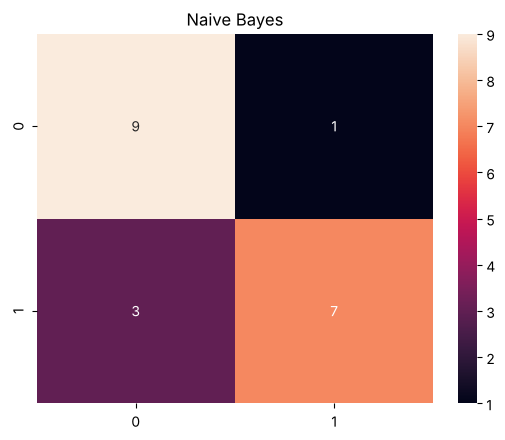

In [3]:
models = {
    "Logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Naive Bayes": make_pipeline(StandardScaler(), GaussianNB())
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

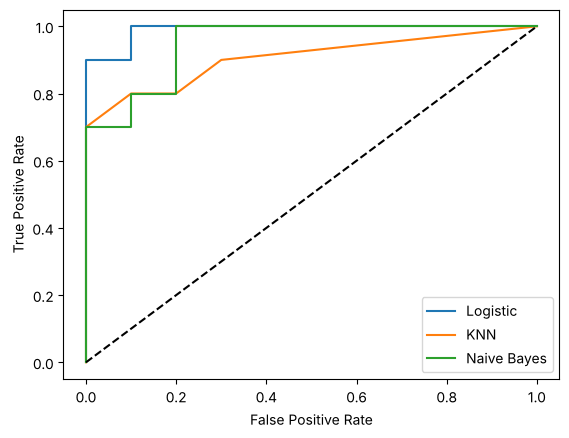

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Logistic regression coefficients and odds ratio

In [5]:
coef = models["Logistic"].named_steps["logisticregression"].coef_[0]
odds = pd.DataFrame({
    "Coefficient": coef,
    "Odds Ratio": np.exp(coef)
}, index=cols)
print(odds)

               Coefficient  Odds Ratio
SepalLengthCm     0.004127    1.004136
SepalWidthCm     -0.386659    0.679323
PetalLengthCm     1.836805    6.276455
PetalWidthCm      2.398646   11.008260


## 5. Effect of K (5-fold CV)

    K  Accuracy        F1       AUC
0   1    0.9750  0.974902  0.975000
1   3    0.9500  0.949804  0.985938
2   5    0.9625  0.963137  0.993750
3   7    0.9625  0.963137  1.000000
4   9    0.9625  0.963137  1.000000
5  11    0.9625  0.963137  1.000000
6  15    0.9625  0.963137  1.000000
Best K: 7


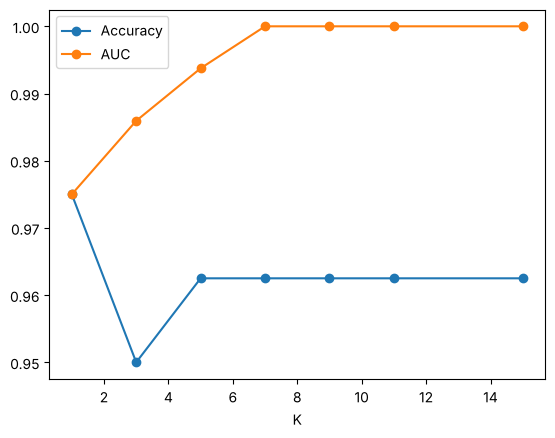

In [6]:
rows = []
for k in [1, 3, 5, 7, 9, 11, 15]:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([k, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

knn = pd.DataFrame(rows, columns=["K", "Accuracy", "F1", "AUC"])
print(knn)
print("Best K:", knn.loc[knn["AUC"].idxmax(), "K"])

knn.plot(x="K", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 6. Comparison and save

             Accuracy  Precision  Recall        F1    AUC
Model                                                    
Logistic         0.90   0.900000     0.9  0.900000  0.990
KNN              0.85   0.888889     0.8  0.842105  0.905
Naive Bayes      0.80   0.875000     0.7  0.777778  0.950


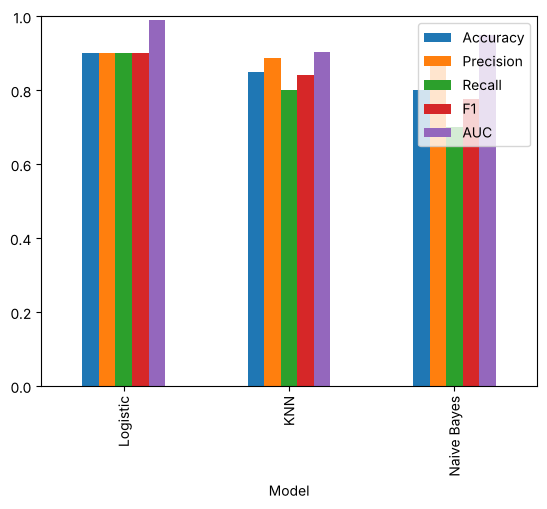

Saved classification.csv, logistic_coefficients.csv, knn_results.csv


In [7]:
result = pd.DataFrame(results, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("classification.csv")
odds.to_csv("logistic_coefficients.csv")
knn.to_csv("knn_results.csv", index=False)
print("Saved classification.csv, logistic_coefficients.csv, knn_results.csv")

## Result / Conclusion
- Task: Versicolor vs Virginica (80 training / 20 test flowers).
- **Logistic Regression is best:** accuracy 0.90, AUC 0.99. KNN reaches 0.85 (AUC 0.905) and Naive Bayes 0.80 (AUC 0.95).
- Odds ratios: +1 SD in petal width multiplies the odds of virginica by 11.0, and petal length by 6.3; sepal length has almost no effect (OR ≈ 1.0).
- 5-fold CV shows KNN is stable for K ≥ 5 (CV accuracy 0.96); best K by AUC = 7. With only 20 test flowers, one mistake changes accuracy by 5%.